<a href="https://colab.research.google.com/github/bhaveshpothula/PBL-Machine-Learning-Projects/blob/main/PBL2_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PBL II — Air Quality State Estimation
**Linear Dynamical Systems · State-Space Modeling · Kalman Filtering**

This complete Google Colab notebook follows the 17-slide **PBL-2.pdf**.

It includes:
1. UCI Air Quality dataset loading and inspection
2. `-200` missing-value handling and chronological 60/20/20 split
3. Missing-value analysis
4. CO and sensor time-series exploration
5. Pearson correlation analysis and sensor-selection justification
6. Linear Dynamical System (LDS) and fitted state parameters
7. State-space model with calibrated S1, S2 and S5 observations
8. Training-only sensor calibration using temperature, relative humidity and absolute humidity
9. Kalman predict/correct implementation
10. Missing-observation handling and uncertainty visualization
11. Validation-based process-noise selection and held-out test evaluation
12. Final result tables and downloadable outputs

**Scope note:** Your PBL-2.pdf covers LDS, State-Space Modeling and Kalman Filtering. This notebook follows those three topics and does not add K-Means or HMM.

Run the notebook from top to bottom. Upload `AirQualityUCI.csv` or `AirQualityUCI.xlsx` when prompted.

## 1. Install and import libraries

In [1]:
!pip -q install numpy pandas matplotlib seaborn scipy scikit-learn openpyxl

import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from google.colab import files

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", 30)
print("Libraries ready.")

Libraries ready.


## 2. Load the dataset already in the Colab Files panel

In [2]:
# Prefer a dataset already present in /content; otherwise prompt for upload.
csv_candidates = glob.glob("/content/**/AirQualityUCI.csv", recursive=True)
xlsx_candidates = glob.glob("/content/**/AirQualityUCI.xlsx", recursive=True)

if not csv_candidates and not xlsx_candidates:
    print("Upload the original UCI dataset: AirQualityUCI.csv or AirQualityUCI.xlsx")
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith(".csv"):
            csv_candidates.append(os.path.abspath(name))
        elif name.lower().endswith((".xlsx", ".xls")):
            xlsx_candidates.append(os.path.abspath(name))

if csv_candidates:
    DATA_PATH = csv_candidates[0]
    raw = pd.read_csv(DATA_PATH, sep=";", decimal=",")
    raw = raw.iloc[:, :15].dropna(how="all")
    stamp = raw["Date"].astype(str) + " " + raw["Time"].astype(str).str.replace(".", ":", regex=False)
    dt = pd.to_datetime(stamp, format="%d/%m/%Y %H:%M:%S", errors="coerce")
elif xlsx_candidates:
    DATA_PATH = xlsx_candidates[0]
    raw = pd.read_excel(DATA_PATH).iloc[:, :15].dropna(how="all")
    date_part = pd.to_datetime(raw["Date"], errors="coerce").dt.strftime("%Y-%m-%d")
    time_part = raw["Time"].astype(str)
    dt = pd.to_datetime(date_part + " " + time_part, errors="coerce")
else:
    raise FileNotFoundError("Please upload AirQualityUCI.csv or AirQualityUCI.xlsx.")

raw = raw.loc[dt.notna()].copy()
dt = dt.loc[dt.notna()]
raw = raw.drop(columns=["Date", "Time"])
raw.index = pd.DatetimeIndex(dt, name="datetime")
raw = raw.sort_index()

NUMERIC_COLS = [
    "CO(GT)", "PT08.S1(CO)", "NMHC(GT)", "C6H6(GT)", "PT08.S2(NMHC)",
    "NOx(GT)", "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)",
    "PT08.S5(O3)", "T", "RH", "AH"
]
raw = raw[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce").astype(float)

print("Loaded:", DATA_PATH)
print("Shape:", raw.shape)
print("Date range:", raw.index.min(), "to", raw.index.max())
display(raw.head())

Upload the original UCI dataset: AirQualityUCI.csv or AirQualityUCI.xlsx


Saving AirQualityUCI.csv to AirQualityUCI.csv
Loaded: /content/AirQualityUCI.csv
Shape: (9357, 13)
Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
datetime,,,,,,,,,,,,,
2004-03-10 18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
2004-03-10 19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2004-03-10 20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
2004-03-10 21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
2004-03-10 22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## 3. Preprocessing: convert -200 to missing values and split chronologically

In [3]:
# In this dataset, -200 is a missing-value sentinel, not a real reading.
missing_sentinel_count = (raw == -200).sum()
data = raw.replace(-200, np.nan)

missing_report = pd.DataFrame({
    "Missing count": data.isna().sum(),
    "Missing percentage": (data.isna().mean() * 100).round(2),
    "Original -200 count": missing_sentinel_count
}).sort_values("Missing percentage", ascending=False)

n = len(data)
n_train = int(n * 0.60)
n_val_end = int(n * 0.80)
train = data.iloc[:n_train].copy()
validation = data.iloc[n_train:n_val_end].copy()
test = data.iloc[n_val_end:].copy()

print("Rows:", n, "| Train:", len(train), "| Validation:", len(validation), "| Test:", len(test))
display(missing_report)
display(pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(train), len(validation), len(test)],
    "Start": [train.index.min(), validation.index.min(), test.index.min()],
    "End": [train.index.max(), validation.index.max(), test.index.max()],
    "Valid CO(GT)": [train["CO(GT)"].notna().sum(), validation["CO(GT)"].notna().sum(), test["CO(GT)"].notna().sum()]
}))

Rows: 9357 | Train: 5614 | Validation: 1871 | Test: 1872


,Missing count,Missing percentage,Original -200 count
NMHC(GT),8443,90.23,8443
CO(GT),1683,17.99,1683
NO2(GT),1642,17.55,1642
NOx(GT),1639,17.52,1639
PT08.S1(CO),366,3.91,366
PT08.S2(NMHC),366,3.91,366
C6H6(GT),366,3.91,366
PT08.S3(NOx),366,3.91,366
PT08.S4(NO2),366,3.91,366
PT08.S5(O3),366,3.91,366


,Split,Rows,Start,End,Valid CO(GT)
0,Train,5614,2004-03-10 18:00:00,2004-10-30 15:00:00,4176
1,Validation,1871,2004-10-30 16:00:00,2005-01-16 14:00:00,1717
2,Test,1872,2005-01-16 15:00:00,2005-04-04 14:00:00,1781


## 4. Missing values per variable (presentation slide 4)

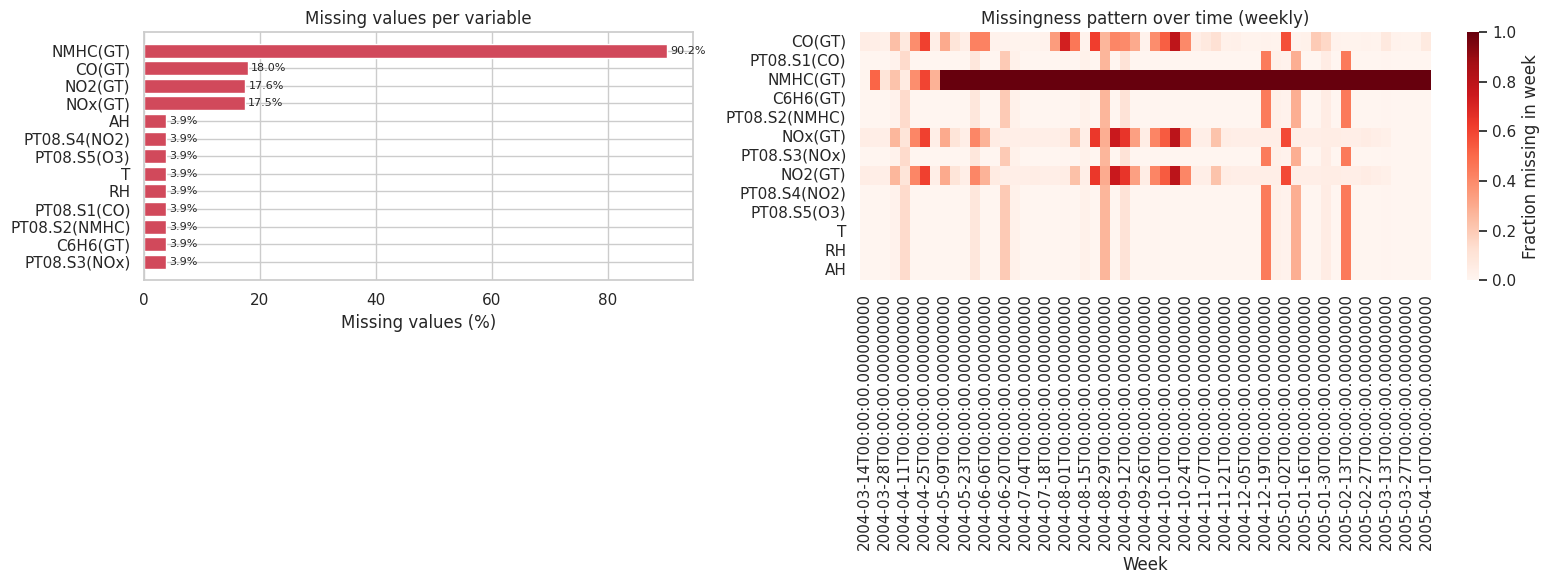

CO(GT) missing: 17.99%
NMHC(GT) missing: 90.23%
Selected sensor average missing: 3.91 %


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 1.3]})
miss = missing_report["Missing percentage"].sort_values()
axes[0].barh(miss.index, miss.values, color="#D1495B")
axes[0].set_xlabel("Missing values (%)")
axes[0].set_title("Missing values per variable")
for i, v in enumerate(miss.values):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)

weekly_missing = data.isna().resample("W").mean().T
sns.heatmap(weekly_missing, cmap="Reds", vmin=0, vmax=1, ax=axes[1],
            cbar_kws={"label": "Fraction missing in week"})
axes[1].set_title("Missingness pattern over time (weekly)")
axes[1].set_xlabel("Week")
plt.tight_layout()
plt.show()

print(f'CO(GT) missing: {missing_report.loc["CO(GT)", "Missing percentage"]:.2f}%')
print(f'NMHC(GT) missing: {missing_report.loc["NMHC(GT)", "Missing percentage"]:.2f}%')
selected_sensors = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)"]
print("Selected sensor average missing:",
      round(missing_report.loc[selected_sensors, "Missing percentage"].mean(), 2), "%")

## 5. Time-series EDA (presentation slide 5)

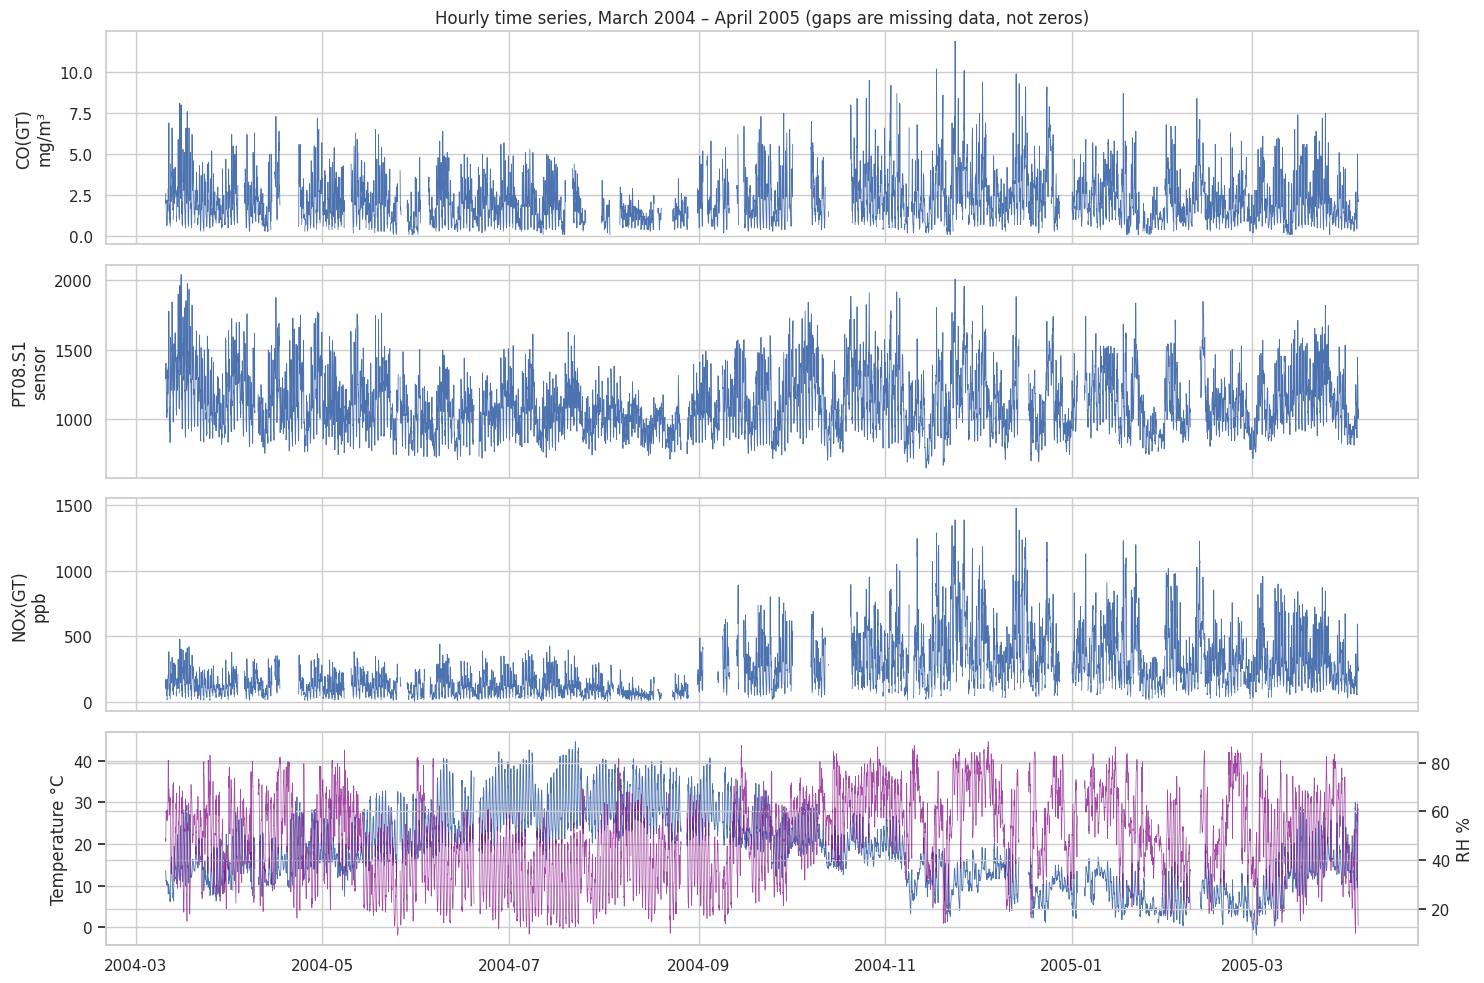

In [5]:
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
axes[0].plot(data.index, data["CO(GT)"], lw=0.6); axes[0].set_ylabel("CO(GT)\nmg/m³")
axes[1].plot(data.index, data["PT08.S1(CO)"], lw=0.6); axes[1].set_ylabel("PT08.S1\nsensor")
axes[2].plot(data.index, data["NOx(GT)"], lw=0.6); axes[2].set_ylabel("NOx(GT)\nppb")
axes[3].plot(data.index, data["T"], lw=0.6, label="Temperature"); axes[3].set_ylabel("Temperature °C")
ax2 = axes[3].twinx()
ax2.plot(data.index, data["RH"], lw=0.5, alpha=0.7, color="purple")
ax2.set_ylabel("RH %")
axes[0].set_title("Hourly time series, March 2004 – April 2005 (gaps are missing data, not zeros)")
plt.tight_layout()
plt.show()

## 6. Correlation matrix (presentation slide 6)

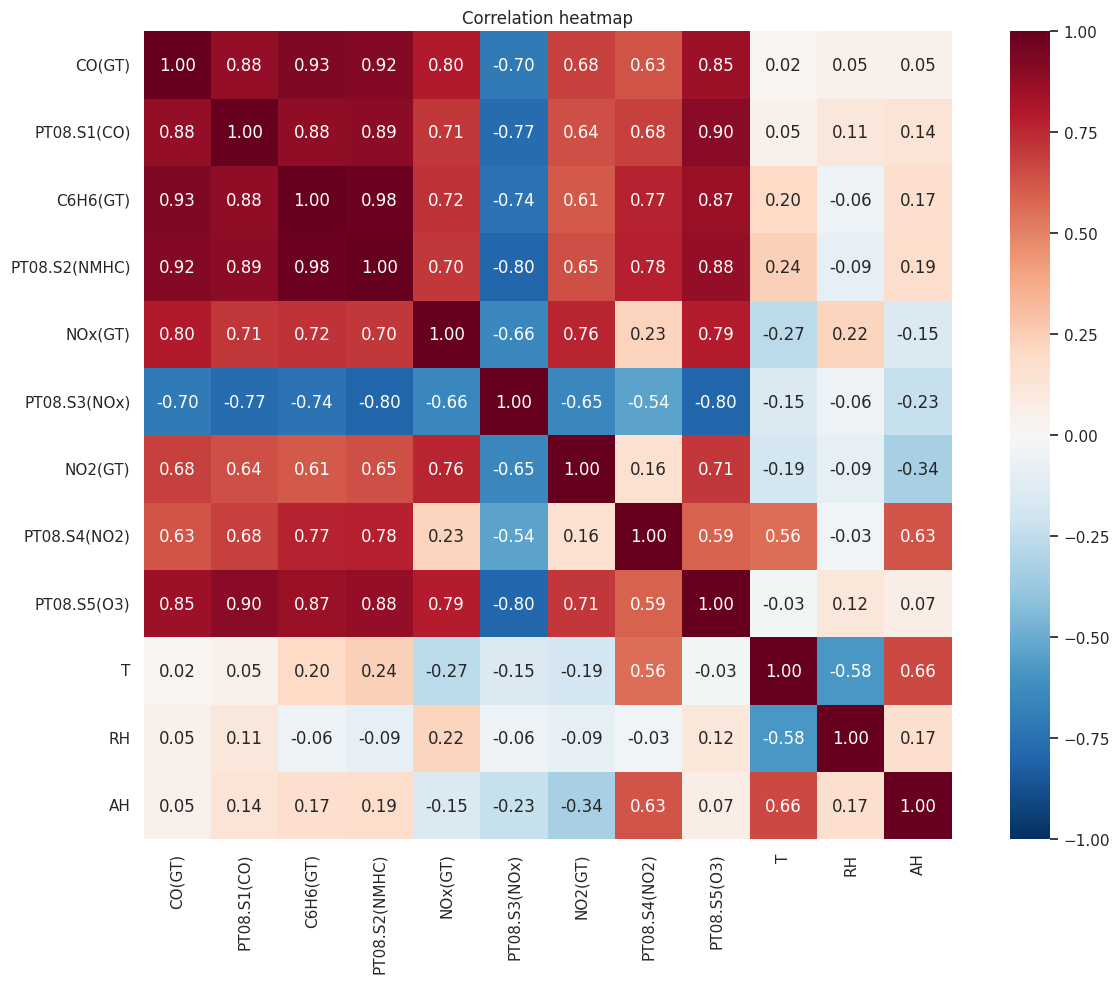

,Pearson correlation with CO(GT)
PT08.S1(CO),0.879288
PT08.S2(NMHC),0.915514
PT08.S5(O3),0.854182
PT08.S3(NOx),-0.703446


In [6]:
corr_cols = [
    "CO(GT)", "PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)",
    "PT08.S3(NOx)", "NO2(GT)", "PT08.S4(NO2)", "PT08.S5(O3)", "T", "RH", "AH"
]
corr = data[corr_cols].corr(method="pearson")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", square=True)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

display(corr["CO(GT)"].loc[
    ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)", "PT08.S3(NOx)"]
].to_frame("Pearson correlation with CO(GT)"))

## 7. Descriptive statistics and pollutant outlier review

This supplementary EDA summarizes the available reference-analyzer measurements. IQR outliers are flagged for review, not automatically removed: high readings can represent genuine pollution episodes.

,Valid count,Mean,Std. dev.,Minimum,Q1,Median,Q3,Maximum
CO(GT),7674.0,2.153,1.453,0.1,1.1,1.8,2.9,11.9
NOx(GT),7718.0,246.897,212.979,2.0,98.0,180.0,326.0,1479.0
NO2(GT),7715.0,113.091,48.370,2.0,78.0,109.0,142.0,340.0


,Variable,Valid n,IQR outliers,Outlier percentage,Lower IQR bound,Upper IQR bound
0,CO(GT),7674,215,2.802,-1.6,5.6
1,NOx(GT),7718,435,5.636,-244.0,668.0
2,NO2(GT),7715,107,1.387,-18.0,238.0


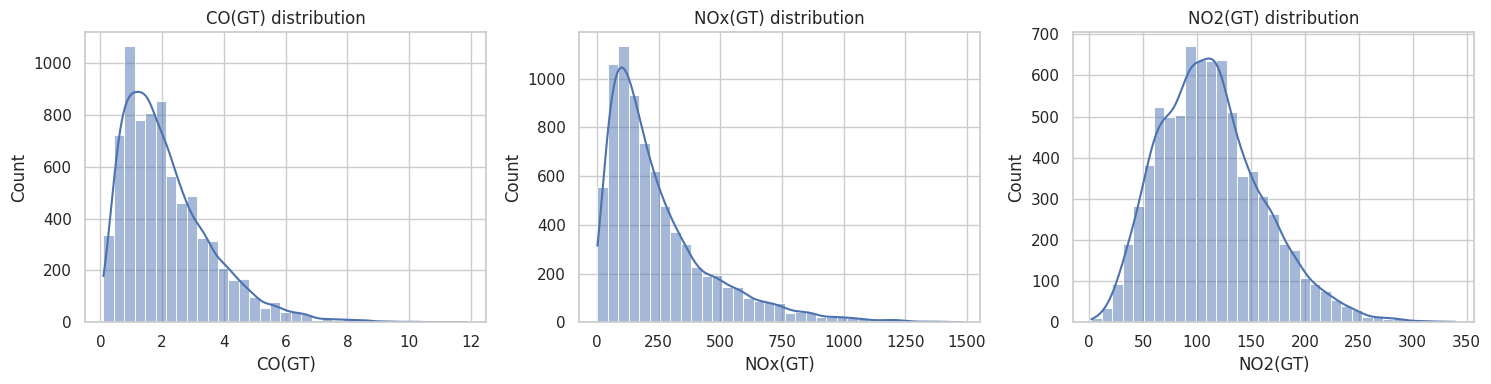

In [7]:
REFERENCE_COLS = ["CO(GT)", "NOx(GT)", "NO2(GT)"]
display(data[REFERENCE_COLS].describe().T.rename(columns={
    "count": "Valid count", "mean": "Mean", "std": "Std. dev.",
    "min": "Minimum", "25%": "Q1", "50%": "Median", "75%": "Q3", "max": "Maximum"
}).round(3))

outlier_rows = []
for col in REFERENCE_COLS:
    s = data[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    count = int(((s < lower) | (s > upper)).sum())
    outlier_rows.append({
        "Variable": col, "Valid n": len(s), "IQR outliers": count,
        "Outlier percentage": 100 * count / len(s) if len(s) else np.nan,
        "Lower IQR bound": lower, "Upper IQR bound": upper
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, REFERENCE_COLS):
    sns.histplot(data[col].dropna(), bins=35, kde=True, ax=ax)
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(col)
plt.tight_layout()
plt.show()

## 8. Linear Dynamical System (LDS) (slides 7–8)

\[
x_t = A x_{t-1} + w_t
\]

The project uses the local-level / random-walk model, with \(A=1\). The initial state and uncertainty are estimated from the training CO data. The process-noise variance \(Q\) is tuned using validation data.

In [8]:
# Training-only state statistics
co_train = train["CO(GT)"]
co_diffs = co_train.diff().dropna()
x0 = float(co_train.mean())
P0 = float(co_train.var())
var_diff = float(co_diffs.var())
pair = pd.concat([co_train.shift(1), co_train], axis=1).dropna()
phi = float((((pair.iloc[:, 0] - x0) * (pair.iloc[:, 1] - x0)).sum()) /
            (((pair.iloc[:, 0] - x0) ** 2).sum()))

A = np.array([[1.0]])
print("A =", A)
print("Initial state x0 =", round(x0, 6))
print("Initial uncertainty P0 =", round(P0, 6))
print("Variance of hourly CO changes =", round(var_diff, 6))
print("Training lag-1 persistence =", round(phi, 4))

A = [[1.]]
Initial state x0 = 2.021791
Initial uncertainty P0 = 1.70192
Variance of hourly CO changes = 0.646117
Training lag-1 persistence = 0.8064


## 9. State-Space Model and sensor calibration (slides 9–11)

\[
x_t = A x_{t-1}+w_t, \qquad z_t=Hx_t+v_t
\]

The three sensors are calibrated using training data only. The calibration uses CO(GT), temperature, relative humidity and absolute humidity. After calibration, each sensor observation is expressed in CO-equivalent units, so \(H=[1,1,1]^T\).

**Important:** CO(GT) is used to fit the calibration and to evaluate the final estimate. It is never passed to the Kalman filter as a measurement.

In [9]:
MET_COLS = ["T", "RH", "AH"]
SENSORS = ["PT08.S1(CO)", "PT08.S2(NMHC)", "PT08.S5(O3)"]

def fit_sensor_calibration(training_df, sensors, use_met=True):
    features = ["CO(GT)"] + (MET_COLS if use_met else [])
    cols = features + sensors
    d = training_df[cols].dropna()
    X = np.column_stack([np.ones(len(d)), d[features].values])
    coefs, residuals = {}, {}
    for sensor in sensors:
        beta, *_ = np.linalg.lstsq(X, d[sensor].values, rcond=None)
        coefs[sensor] = beta
        residuals[sensor] = (d[sensor].values - X @ beta) / beta[1]
    R = np.atleast_2d(np.cov(np.vstack([residuals[s] for s in sensors])))
    return coefs, R, len(d)

def transform_sensors(frame, coefs, sensors, use_met=True):
    out = []
    for sensor in sensors:
        beta = coefs[sensor]
        met_effect = frame[MET_COLS].values @ beta[2:] if use_met else 0.0
        baseline = beta[0] + met_effect
        out.append((frame[sensor].values - baseline) / beta[1])
    return np.column_stack(out)

coefs, R, calibration_rows = fit_sensor_calibration(train, SENSORS, use_met=True)
Z = transform_sensors(data, coefs, SENSORS, use_met=True)
H = np.ones((3, 1))

print("Training rows used for calibration:", calibration_rows)
print("Observation matrix H =\n", H)
print("Measurement covariance R =")
display(pd.DataFrame(R, index=["S1", "S2", "S5"], columns=["S1", "S2", "S5"]))
calibration_table = pd.DataFrame(coefs, index=["Intercept", "CO gain", "T coefficient", "RH coefficient", "AH coefficient"]).T
calibration_table["CO-equivalent residual SD"] = np.sqrt(np.diag(R))
display(calibration_table)

Training rows used for calibration: 4061
Observation matrix H =
 [[1.]
 [1.]
 [1.]]
Measurement covariance R =


,S1,S2,S5
S1,0.363080,0.072319,0.180843
S2,0.072319,0.157022,0.159035
S5,0.180843,0.159035,0.487544


,Intercept,CO gain,T coefficient,RH coefficient,AH coefficient,CO-equivalent residual SD
PT08.S1(CO),812.226859,146.945310,-2.848490,0.123808,43.483625,0.602561
PT08.S2(NMHC),423.425782,181.107513,6.921867,0.779095,-13.992102,0.396260
PT08.S5(O3),396.483476,241.488692,-2.763429,0.550802,123.885527,0.698243


## 10. Kalman filter implementation: prediction, correction and missing data

In [10]:
class KalmanFilter:
    def __init__(self, A, H, Q, R, x0, P0):
        self.A = np.atleast_2d(np.asarray(A, float))
        self.H = np.atleast_2d(np.asarray(H, float))
        self.Q = np.atleast_2d(np.asarray(Q, float))
        self.R = np.atleast_2d(np.asarray(R, float))
        self.x0 = np.asarray(x0, float).ravel()
        self.P0 = np.atleast_2d(np.asarray(P0, float))
        self.n = self.A.shape[0]

    def predict(self, x, P):
        xp = self.A @ x
        Pp = self.A @ P @ self.A.T + self.Q
        return xp, Pp

    def update(self, xp, Pp, z):
        observed = ~np.isnan(z)
        if not observed.any():
            return xp, Pp
        Hs = self.H[observed]
        Rs = self.R[np.ix_(observed, observed)]
        innovation = z[observed] - Hs @ xp
        S = Hs @ Pp @ Hs.T + Rs
        K = np.linalg.solve(S, Hs @ Pp).T
        x = xp + K @ innovation
        I_KH = np.eye(self.n) - K @ Hs
        # Joseph covariance update for numerical stability
        P = I_KH @ Pp @ I_KH.T + K @ Rs @ K.T
        return x, P

    def filter(self, observations):
        T = observations.shape[0]
        xf = np.zeros((T, self.n))
        Pf = np.zeros((T, self.n, self.n))
        xp_all = np.zeros_like(xf)
        Pp_all = np.zeros_like(Pf)
        x, P = self.x0.copy(), self.P0.copy()
        for t in range(T):
            if t == 0:
                xp, Pp = x, P
            else:
                xp, Pp = self.predict(x, P)
            x, P = self.update(xp, Pp, observations[t])
            xf[t], Pf[t] = x, P
            xp_all[t], Pp_all[t] = xp, Pp
        return {"x_filt": xf, "P_filt": Pf, "x_pred": xp_all, "P_pred": Pp_all}

def run_local_level_filter(Z, q, R, x0, P0):
    kf = KalmanFilter(A=[[1.0]], H=np.ones((Z.shape[1], 1)), Q=[[q]], R=R,
                      x0=[x0], P0=[[P0]])
    result = kf.filter(Z)
    estimate = pd.Series(result["x_filt"][:, 0], index=data.index)
    uncertainty = pd.Series(np.sqrt(result["P_filt"][:, 0, 0]), index=data.index)
    return estimate, uncertainty, kf, result

print("Kalman filter class ready. Missing sensor values (NaN) are ignored in the update step.")

Kalman filter class ready. Missing sensor values (NaN) are ignored in the update step.


## 11. Tune process noise Q on validation data and evaluate once on test data

In [11]:
# Match the project strategy: Q = multiplier * variance(hourly CO changes).
# Choose Q using validation RMSE only; the test set is not used for tuning.

pos = np.arange(len(data))
val_mask = (pos >= n_train) & (pos < n_val_end)
test_mask = pos >= n_val_end
y = data["CO(GT)"]

def score_metrics(y_true, y_pred, mask):
    m = mask & y_true.notna().values & y_pred.notna().values
    yt, yp = y_true.values[m], y_pred.values[m]
    return {
        "N": int(m.sum()),
        "RMSE": float(np.sqrt(mean_squared_error(yt, yp))),
        "MAE": float(mean_absolute_error(yt, yp)),
        "R2": float(r2_score(yt, yp))
    }

q_multipliers = np.logspace(-1.5, 2.0, 15)
q_rows = []
for mult in q_multipliers:
    q = var_diff * mult
    est, sd, kf, result = run_local_level_filter(Z, q, R, x0, P0)
    metrics = score_metrics(y, est, val_mask)
    q_rows.append({"Q multiplier": mult, "Q": q, "Validation RMSE": metrics["RMSE"]})

q_table = pd.DataFrame(q_rows).sort_values("Validation RMSE")
display(q_table)
best_q = float(q_table.iloc[0]["Q"])
print("Selected Q:", best_q)

kalman_estimate, kalman_sd, kf, kf_result = run_local_level_filter(Z, best_q, R, x0, P0)
test_metrics = score_metrics(y, kalman_estimate, test_mask)
print("Unseen test metrics:")
display(pd.DataFrame([test_metrics]))

,Q multiplier,Q,Validation RMSE
6,1.000000,0.646117,0.841548
5,0.562341,0.363338,0.843068
7,1.778279,1.148976,0.843965
8,3.162278,2.043201,0.847170
9,5.623413,3.633381,0.849823
10,10.000000,6.461167,0.851656
11,17.782794,11.489761,0.852812
12,31.622777,20.432005,0.853505
4,0.316228,0.204320,0.853520
13,56.234133,36.333814,0.853908


Selected Q: 0.6461167421073195
Unseen test metrics:


,N,RMSE,MAE,R2
0,1781,0.752197,0.452705,0.700129


## 12. Baseline comparisons on the same test observations

In [12]:
# Calibrated S1 and static sensor fusion baselines.
def static_fusion(Z, R, index):
    fused = np.full(Z.shape[0], np.nan)
    for t in range(Z.shape[0]):
        obs = ~np.isnan(Z[t])
        if obs.any():
            Ri = np.linalg.inv(R[np.ix_(obs, obs)])
            one = np.ones(obs.sum())
            fused[t] = (one @ Ri @ Z[t, obs]) / (one @ Ri @ one)
    return pd.Series(fused, index=index)

static_est = static_fusion(Z, R, data.index)
s1_est = pd.Series(Z[:, 0], index=data.index)
ema_est = static_est.ewm(alpha=0.3, adjust=False).mean()

baseline_rows = []
for name, pred in [
    ("Calibrated S1", s1_est),
    ("Static fusion S1+S2+S5", static_est),
    ("EMA fusion (alpha=0.3)", ema_est),
    ("Kalman local-level fusion", kalman_estimate)
]:
    m = test_mask & y.notna().values & pred.notna().values
    baseline_rows.append({"Method": name, **score_metrics(y, pred, test_mask)})

comparison = pd.DataFrame(baseline_rows).sort_values("RMSE")
display(comparison.round(4))

,Method,N,RMSE,MAE,R2
1,Static fusion S1+S2+S5,1696,0.5775,0.4069,0.8145
3,Kalman local-level fusion,1781,0.7522,0.4527,0.7001
0,Calibrated S1,1696,0.7908,0.5944,0.6522
2,EMA fusion (alpha=0.3),1781,0.9539,0.6467,0.5178


## 13. Plot the Kalman estimate on an unseen test window (presentation slide 15)

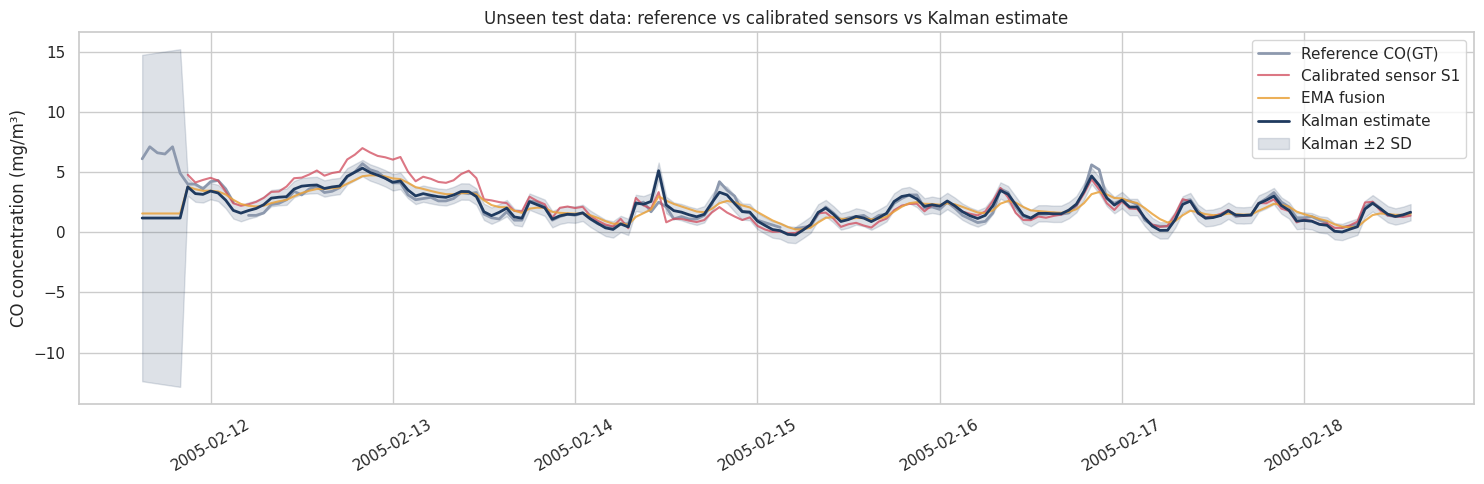

In [13]:
test_positions = np.flatnonzero(test_mask)
window_start = test_positions[len(test_positions)//3]
window_end = min(window_start + 7*24, len(data))
sl = slice(window_start, window_end)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(data.index[sl], y.iloc[sl], label="Reference CO(GT)", linewidth=2, color="#8D99AE")
ax.plot(data.index[sl], s1_est.iloc[sl], label="Calibrated sensor S1", alpha=0.75, color="#D1495B")
ax.plot(data.index[sl], ema_est.iloc[sl], label="EMA fusion", alpha=0.85, color="#E9A23B")
ax.plot(data.index[sl], kalman_estimate.iloc[sl], label="Kalman estimate", linewidth=2, color="#1F3A5F")
ax.fill_between(data.index[sl],
                kalman_estimate.iloc[sl] - 2*kalman_sd.iloc[sl],
                kalman_estimate.iloc[sl] + 2*kalman_sd.iloc[sl],
                alpha=0.15, color="#1F3A5F", label="Kalman ±2 SD")
ax.set_ylabel("CO concentration (mg/m³)")
ax.set_title("Unseen test data: reference vs calibrated sensors vs Kalman estimate")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 14. Missing sensor observations: show uncertainty behaviour (presentation slide 14)

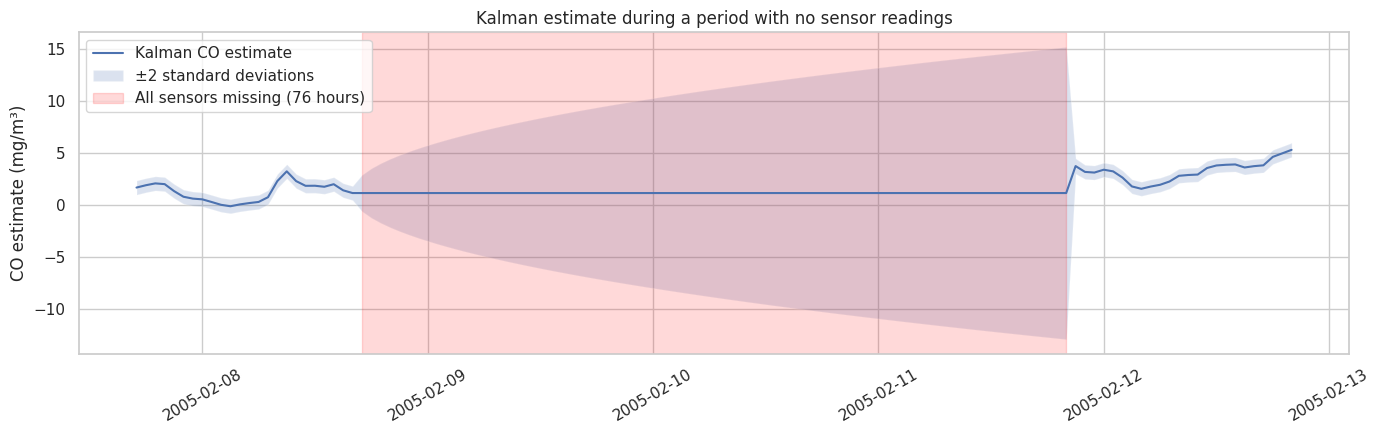

Longest all-sensor gap: 76 hours


In [14]:
all_sensors_missing = np.isnan(Z).all(axis=1)
edge = np.diff(np.r_[False, all_sensors_missing, False].astype(int))
starts, stops = np.where(edge == 1)[0], np.where(edge == -1)[0]

if len(starts):
    gap_start, gap_stop = max(zip(starts, stops), key=lambda p: p[1]-p[0])
    left, right = max(0, gap_start-24), min(len(data), gap_stop+24)
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.plot(data.index[left:right], kalman_estimate.iloc[left:right], label="Kalman CO estimate")
    ax.fill_between(data.index[left:right],
                    kalman_estimate.iloc[left:right] - 2*kalman_sd.iloc[left:right],
                    kalman_estimate.iloc[left:right] + 2*kalman_sd.iloc[left:right],
                    alpha=0.2, label="±2 standard deviations")
    ax.axvspan(data.index[gap_start], data.index[gap_stop-1], color="red", alpha=0.15,
               label=f"All sensors missing ({gap_stop-gap_start} hours)")
    ax.set_ylabel("CO estimate (mg/m³)")
    ax.set_title("Kalman estimate during a period with no sensor readings")
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    print("Longest all-sensor gap:", gap_stop-gap_start, "hours")
else:
    print("No simultaneous all-sensor gap found. The filter still handles individual missing channels.")

## 15. Final project summary and save outputs

In [15]:
print("PROJECT SUMMARY")
print("LDS: A = 1.0")
print("Initial state x0 =", round(x0, 3), "| Initial uncertainty P0 =", round(P0, 3))
print("Selected process noise Q =", round(best_q, 6))
print("State-space: hidden state = CO; observations = calibrated S1, S2, S5")
print("H = [1, 1, 1]^T")
print("R matrix:")
display(pd.DataFrame(R, index=["S1","S2","S5"], columns=["S1","S2","S5"]))
print("Kalman test metrics:")
display(pd.DataFrame([test_metrics]).round(4))

os.makedirs("/content/Air_Quality_Colab_Results", exist_ok=True)
outdir = "/content/Air_Quality_Colab_Results"
missing_report.to_csv(outdir + "/missing_values_per_variable.csv")
data.describe().T.to_csv(outdir + "/descriptive_statistics.csv")
outlier_summary.to_csv(outdir + "/outlier_summary.csv", index=False)
corr.to_csv(outdir + "/correlation_matrix.csv")
calibration_table.to_csv(outdir + "/sensor_calibration_parameters.csv")
q_table.to_csv(outdir + "/Q_validation_tuning.csv", index=False)
comparison.to_csv(outdir + "/test_comparison.csv", index=False)
pd.DataFrame({
    "CO_reference": y,
    "Kalman_estimate": kalman_estimate,
    "Kalman_standard_deviation": kalman_sd,
    "Calibrated_S1": s1_est,
    "Static_fusion": static_est
}).to_csv(outdir + "/kalman_estimates.csv")
print("Saved CSV result files in", outdir)

PROJECT SUMMARY
LDS: A = 1.0
Initial state x0 = 2.022 | Initial uncertainty P0 = 1.702
Selected process noise Q = 0.646117
State-space: hidden state = CO; observations = calibrated S1, S2, S5
H = [1, 1, 1]^T
R matrix:


,S1,S2,S5
S1,0.363080,0.072319,0.180843
S2,0.072319,0.157022,0.159035
S5,0.180843,0.159035,0.487544


Kalman test metrics:


,N,RMSE,MAE,R2
0,1781,0.7522,0.4527,0.7001


Saved CSV result files in /content/Air_Quality_Colab_Results


## 16. Download result tables as a ZIP

In [16]:
import shutil
from google.colab import files
shutil.make_archive("/content/Air_Quality_Colab_Results", "zip", outdir)
files.download("/content/Air_Quality_Colab_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Viva quick recap
- **LDS:** models how hidden CO changes over time: \(x_t=Ax_{t-1}+w_t\).
- **State-space:** connects the hidden CO state to calibrated sensor observations.
- **Kalman filter:** predicts, then corrects using available sensor readings.
- **Missing data:** missing channels are skipped; if all are missing, prediction continues and uncertainty grows.
- **Correlation matrix:** helps justify why S1, S2 and S5 were selected.
- **CO(GT):** used for calibration and scoring only, never fed as a Kalman measurement.